1.Importing libraries


In [30]:

# Data manipulation
import numpy as np
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV


2.Load the dataset


In [3]:

df = pd.read_csv('/content/Housing.csv')
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


3.Understanding the Dataset

In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [7]:

# Display first 5 records
display(df.head())

# Display last 5 records
display(df.tail())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)



,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


Dataset Shape: (545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingst

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000



Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records: 0

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


 4. Data cleaning

In [8]:

# Create a copy of the original dataset
df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing target prices
df = df.dropna(subset=["price"])

# Check the cleaned dataset
print("Shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Shape after cleaning: (545, 13)

Missing values after cleaning:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


5.Exploratory Data Analysis (EDA)

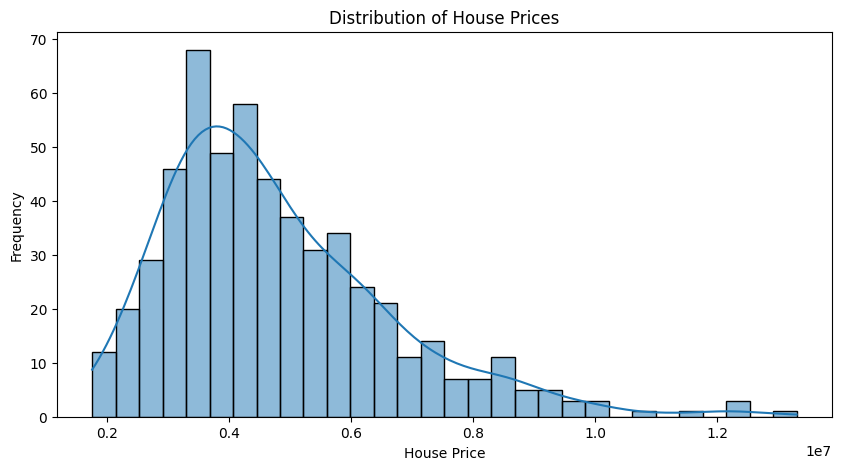

In [9]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df["price"],
    kde=True,
    bins=30
)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()


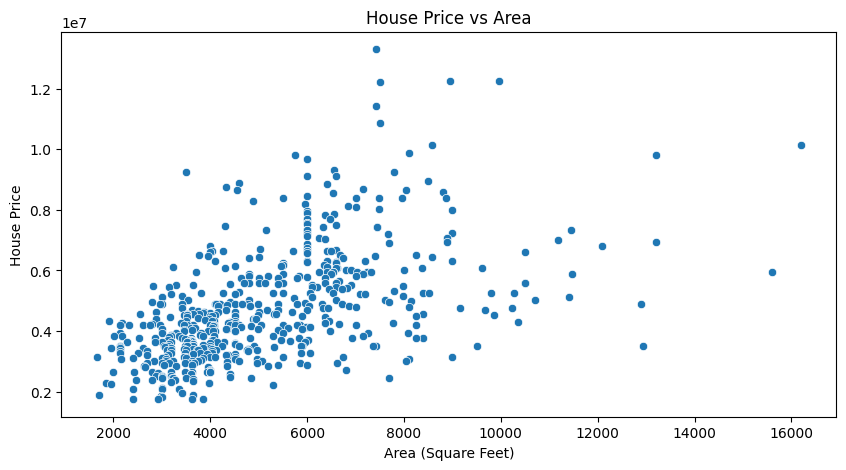

In [10]:
#House prices based on area

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="area",
    y="price"
)

plt.title("House Price vs Area")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price")

plt.show()



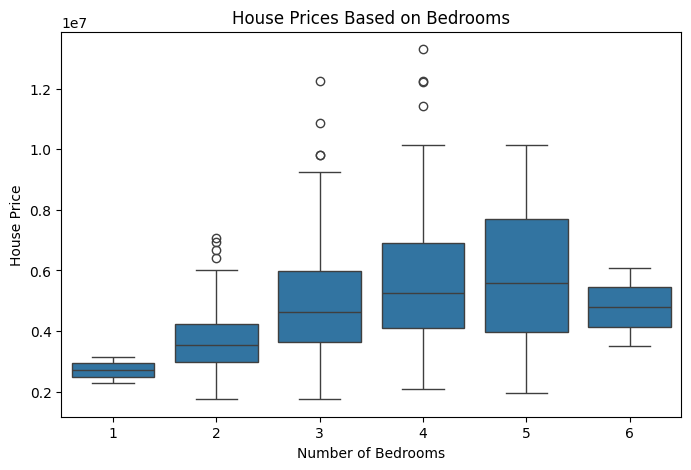

In [11]:
#House prices based on bedrooms

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="price"
)

plt.title("House Prices Based on Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price")

plt.show()


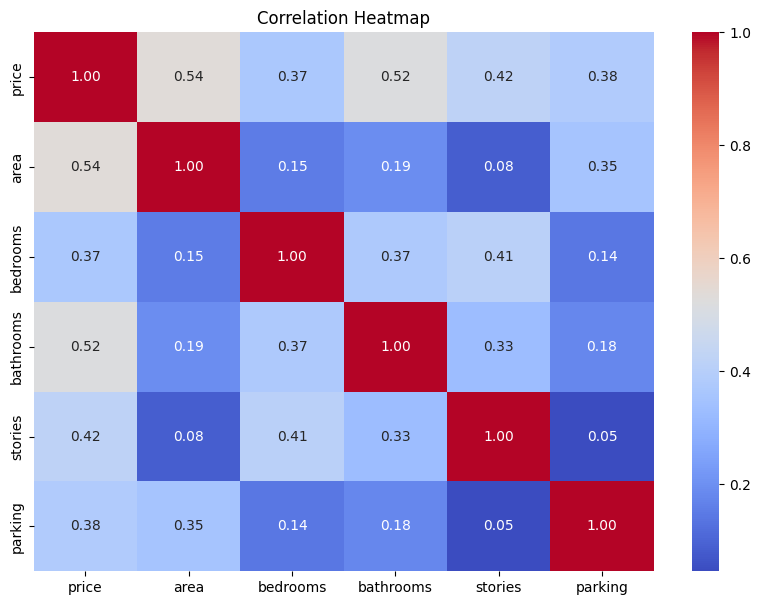

In [12]:
#Correlation heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


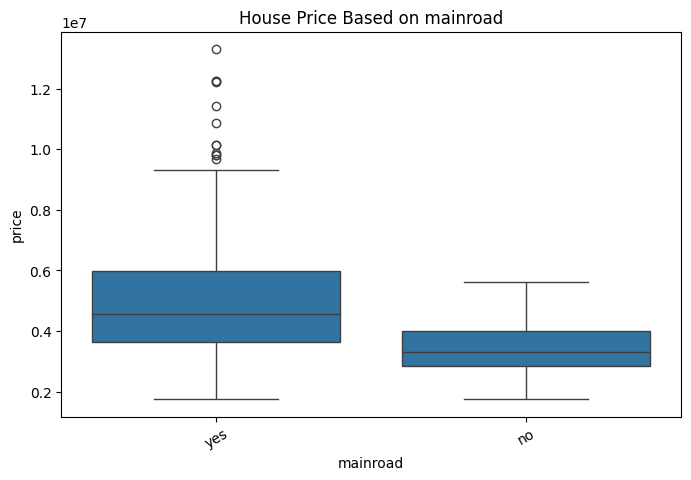

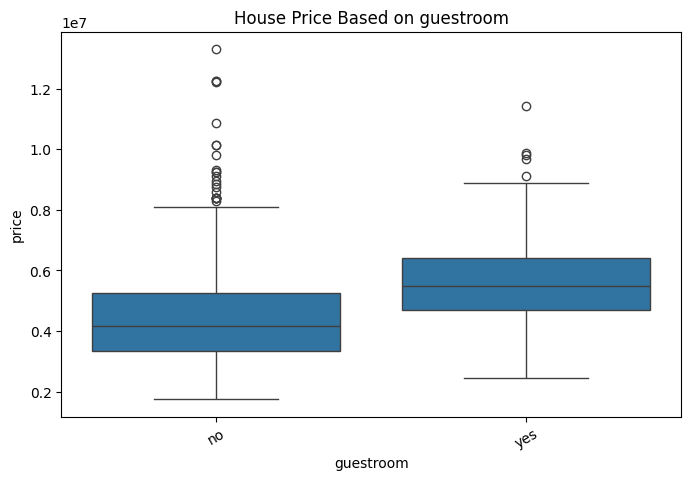

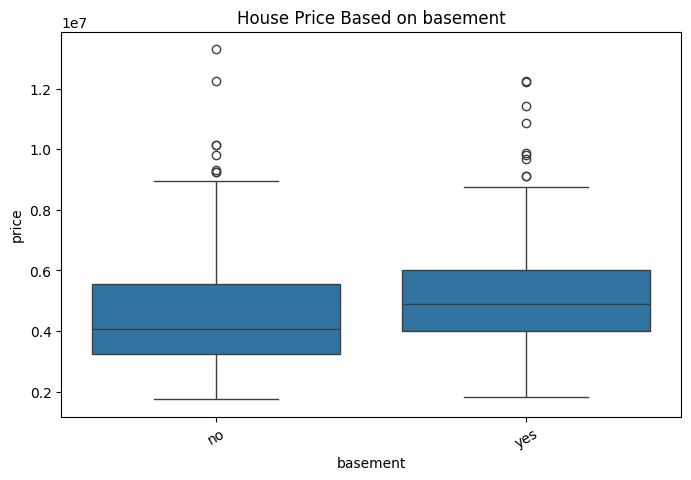

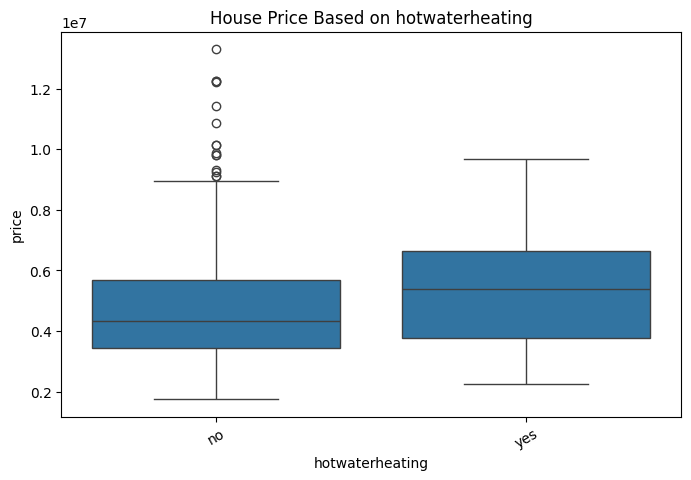

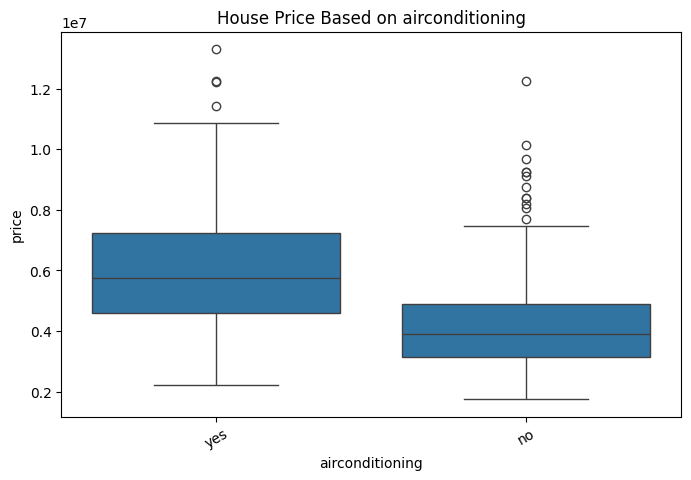

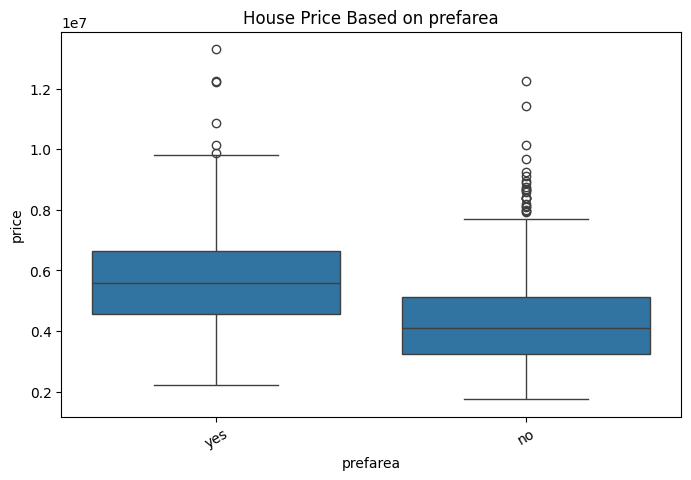

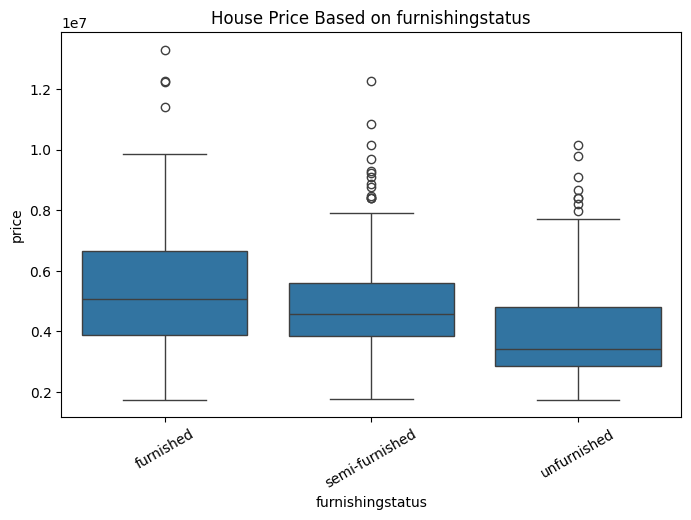

In [13]:
#Categorical feature analysis

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=column,
        y="price"
    )

    plt.title(f"House Price Based on {column}")

    plt.xticks(rotation=30)

    plt.show()


6.Feature engineering

In [14]:

# Define input features
X = df.drop("price", axis=1)

# Define target variable
y = df["price"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Input Features:
   area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  7420         4          2        3      yes        no       no   
1  8960         4          4        4      yes        no       no   
2  9960         3          2        2      yes        no      yes   
3  7500         4          2        2      yes        no      yes   
4  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Target Variable:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64

Feature Shape: (545, 12)
Tar

In [15]:
#Separate numerical and categorical columns.

# Identify numerical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical Features:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


7.Train-test split

In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,test_size=0.20,random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (436, 12)
Testing Data: (109, 12)


8.Data preprocessing

In [20]:

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


7.Create and train multiple machine learning models

In [23]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

In [24]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "training completed")

Linear Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


8.Evaluate all four models

In [25]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="R2 Score",
    ascending=False
))

               Model           MAE           MSE          RMSE  R2 Score
3  Gradient Boosting  9.696879e+05  1.695341e+12  1.302053e+06  0.664592
0  Linear Regression  9.700434e+05  1.754319e+12  1.324507e+06  0.652924
2      Random Forest  1.025961e+06  1.971006e+12  1.403925e+06  0.610055
1      Decision Tree  1.234858e+06  2.888729e+12  1.699626e+06  0.428492


9.Visualise model performance

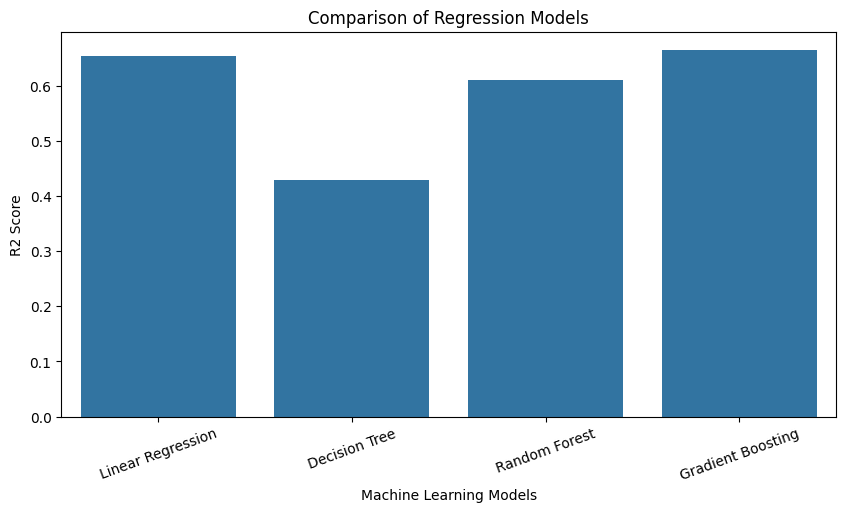

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Regression Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)
plt.show()

10.Hyperparameter tuning using GridSearchCV

In [27]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]
)

In [28]:
#Define the parameters
param_grid = {
    "model__n_estimators": [100, 200, 300],

    "model__max_depth": [None, 10, 20],

    "model__min_samples_split": [2, 5],

    "model__min_samples_leaf": [1, 2]
}

In [31]:
#Run GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['area',
                                                                          'bedrooms',
                                                                          'bathrooms',
                                                                          'stories',
                                                                          'parking']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('encoder',
                                                                                          OneHotEncoder(handle_...='ignore'))]),
                                                                         ['mainroad',
                                                                          'guestroom',
                                                                          'basement',
                                                                          'hotwaterheating',
                                                                          'airconditioning',
                                                                          'prefarea',
                                                                          'furnishingstatus'])])),
                                       ('model',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200, 300]},
             scoring='r2', verbose=1)

In [32]:
#Find the best parameters:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross Validation R2 Score:")
print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Cross Validation R2 Score:
0.6156102770248529


11.Evaluate the tuned model

In [33]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Final Model Evaluation")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Final Model Evaluation
MAE: 1053413.5227755168
MSE: 2046886521773.5537
RMSE: 1430694.4194249008
R2 Score: 0.5950424225981017


12.Actual vs predicted price visualisation

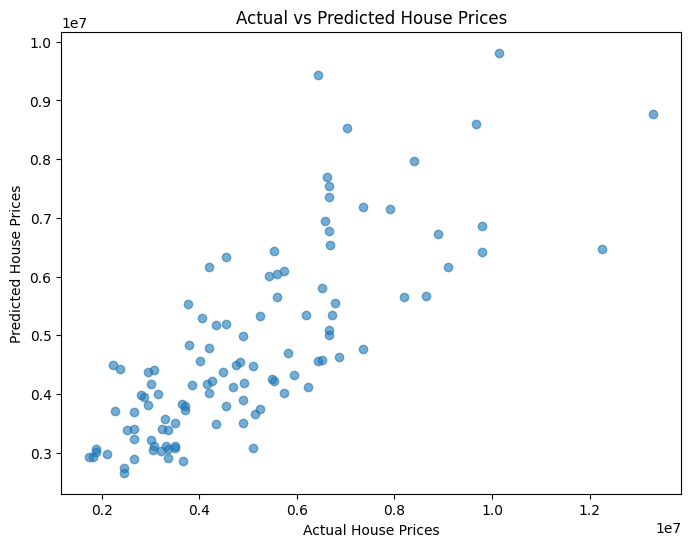

In [34]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

13.Analyse feature importance

In [35]:
rf_model = best_model.named_steps["model"]

feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df)

                                 Feature  Importance
0                              num__area    0.483414
2                         num__bathrooms    0.157941
3                           num__stories    0.052212
4                           num__parking    0.048985
1                          num__bedrooms    0.041207
14              cat__airconditioning_yes    0.037264
19     cat__furnishingstatus_unfurnished    0.034933
13               cat__airconditioning_no    0.029188
10                     cat__basement_yes    0.017120
9                       cat__basement_no    0.015935
16                     cat__prefarea_yes    0.015264
15                      cat__prefarea_no    0.014782
17       cat__furnishingstatus_furnished    0.009822
8                     cat__guestroom_yes    0.008901
18  cat__furnishingstatus_semi-furnished    0.007664
7                      cat__guestroom_no    0.006157
11               cat__hotwaterheating_no    0.005439
12              cat__hotwaterheating_yes    0.

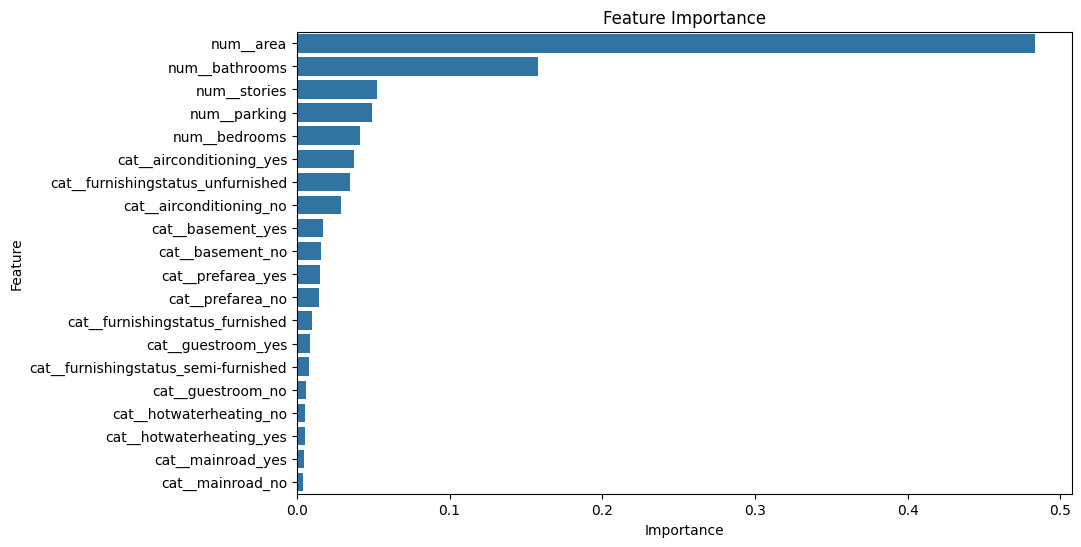

In [36]:
#Visualise the results
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

14.Save the trained model

In [38]:
import joblib
joblib.dump(
    best_model,
    "house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
loaded_model = joblib.load(
    "house_price_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


15.Predict the price of a new house

In [40]:
new_house = pd.DataFrame([{
    "area": 6000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "yes",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 2,
    "prefarea": "yes",
    "furnishingstatus": "furnished"
}])

In [41]:
#Predict the price
predicted_price = loaded_model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 8613109.973333335
